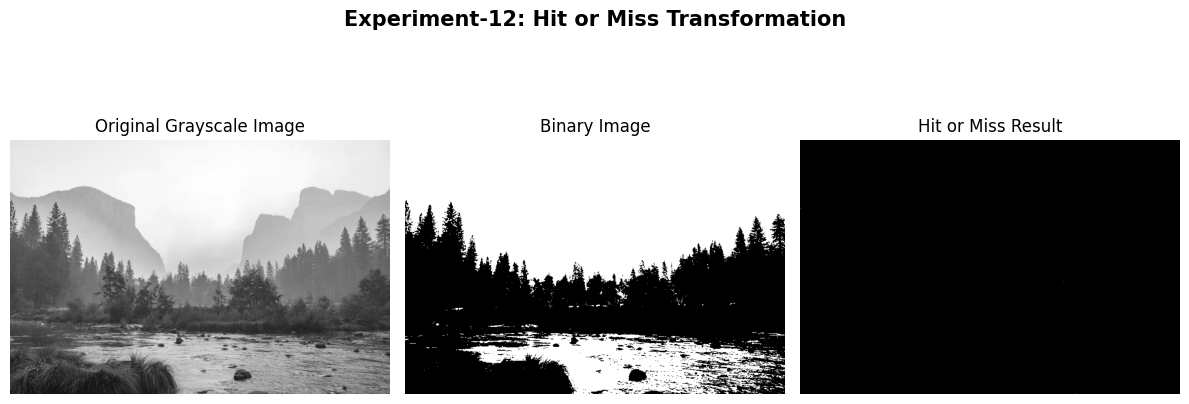

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Read image
# ---------------------------------------

image = cv2.imread("image.png", cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Error: Image not found!")
    exit()

# ---------------------------------------
# 2. Convert image to binary
#    Hit-or-Miss requires 0 and 1
# ---------------------------------------

_, binary = cv2.threshold(
    image,
    127,
    1,
    cv2.THRESH_BINARY
)

# ---------------------------------------
# 3. Define Hit-or-Miss pattern
#
#  1  = foreground (Hit)
# -1  = background (Miss)
#  0  = Don't care
# ---------------------------------------

pattern = np.array([
    [-1,  1, -1],
    [ 1,  1,  1],
    [-1,  1, -1]
], dtype=np.int8)

# ---------------------------------------
# 4. Apply Hit-or-Miss Transformation
# ---------------------------------------

result = cv2.morphologyEx(
    binary,
    cv2.MORPH_HITMISS,
    pattern
)

# ---------------------------------------
# 5. Convert for display
# ---------------------------------------

binary_display = binary * 255
result_display = result * 255

# ---------------------------------------
# 6. Display results
# ---------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_display, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result_display, cmap="gray")
plt.title("Hit or Miss Result")
plt.axis("off")

plt.suptitle(
    "Experiment-12: Hit or Miss Transformation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()